In [3]:
import pandas as pd
import folium
from folium.plugins import MarkerCluster, HeatMap

df = pd.read_csv("airports-india.csv")

df.columns = df.columns.str.strip()

df = df.dropna(subset=["latitude", "longitude"])
df = df[
    df["latitude"].between(6, 38) &
    df["longitude"].between(68, 98)
]

print("Total airports:", len(df))
print(df.head())

Total airports: 201
                                             name  latitude  longitude  \
0                                  Mumbai Airport  19.08869   72.86792   
1             Indira Gandhi International Airport  28.56650   77.10309   
2  Sardar Vallabhbhai Patel International Airport  23.07724   72.63465   
3     Sri Guru Ram Dass Jee International Airport  31.70959   74.79726   
4                   Chennai International Airport  12.98833   80.16578   

  country       region  elevation_m  population feature_type  geoname_id  
0   India  Maharashtra         11.0           0      airport     6301032  
1   India        Delhi        236.0           0      airport     6301872  
2   India      Gujarat         57.0           0      airport     6301029  
3   India       Punjab        230.0           0      airport     6301092  
4   India   Tamil Nadu         15.0           0      airport     6301127  


In [4]:
m = folium.Map(
    location=[22.5, 79],
    zoom_start=5
)

for _, row in df.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=4,
        popup=row["name"],
        tooltip=row["name"],
        color="blue",
        fill=True,
        fill_opacity=0.7
    ).add_to(m)

m.save("point_map.html")
print("Point map saved!")

Point map saved!


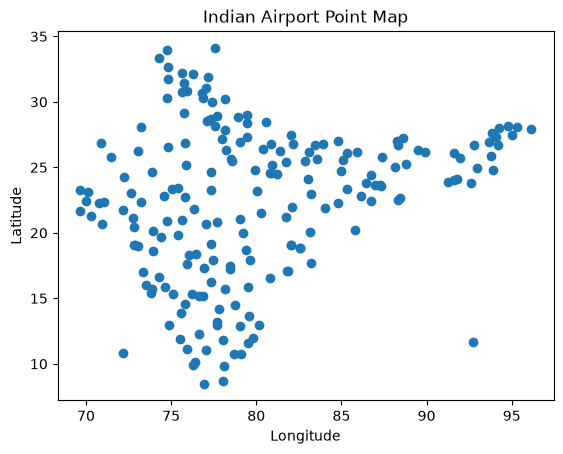

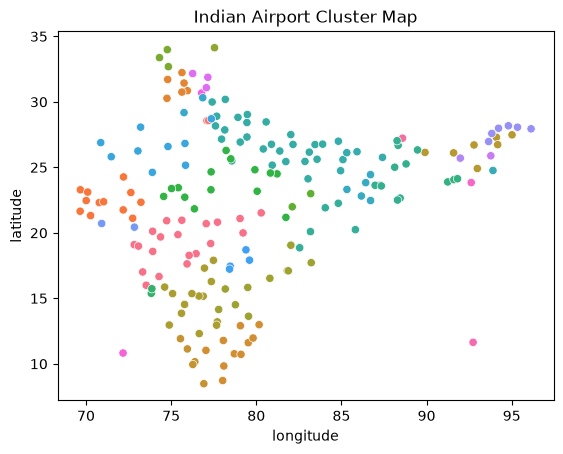

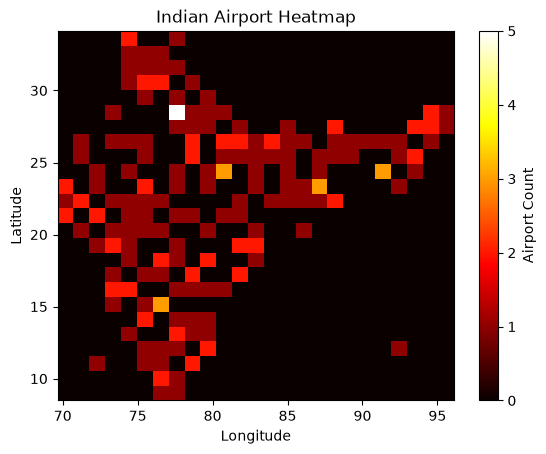

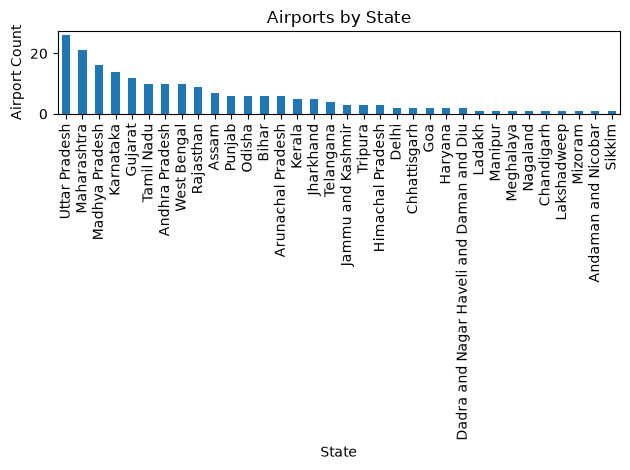

ValueError: DataFrame index must be unique for orient='index'.

In [11]:


import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns

# Load dataset
df = pd.read_csv("airports-india.csv")
df.columns = df.columns.str.strip()
df = df.dropna(subset=["latitude", "longitude"])
df = df[df["latitude"].between(6, 38) &
        df["longitude"].between(68, 98)]

# 1. Point Map
plt.figure()
plt.scatter(df.longitude, df.latitude)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Indian Airport Point Map")
plt.show()

# 2. Cluster Map
plt.figure()
sns.scatterplot(data=df, x="longitude", y="latitude",
                hue="region", legend=False)
plt.title("Indian Airport Cluster Map")
plt.show()

# 3. Heatmap
plt.figure()
plt.hist2d(df.longitude, df.latitude, bins=25, cmap="hot")
plt.colorbar(label="Airport Count")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Indian Airport Heatmap")
plt.show()

# 4. Airport Count by State
plt.figure()
df["region"].value_counts().plot(kind="bar")
plt.xlabel("State")
plt.ylabel("Airport Count")
plt.title("Airports by State")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 5. Flow Map (sample connections)
routes = [
    ("Mumbai Airport", "Indira Gandhi International Airport"),
    ("Indira Gandhi International Airport",
     "Chennai International Airport"),
    ("Mumbai Airport",
     "Sardar Vallabhbhai Patel International Airport")
]

coords = df.set_index("name")[["latitude", "longitude"]].to_dict("index")

plt.figure()
plt.scatter(df.longitude, df.latitude, s=10)

for src, dst in routes:
    if src in coords and dst in coords:
        a, b = coords[src], coords[dst]
        plt.plot([a["longitude"], b["longitude"]],
                 [a["latitude"], b["latitude"]], "r-")

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Indian Airport Flow Map (Illustrative Routes)")
plt.show()


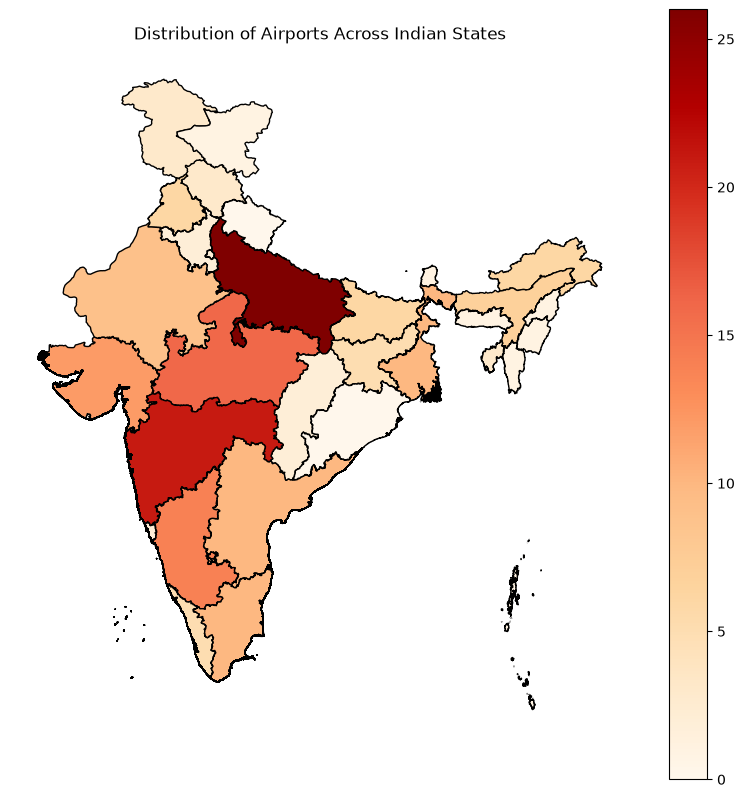

In [26]:
import geopandas as gpd
import matplotlib.pyplot as plt

states = gpd.read_file("india-states-full.geojson")

# Count airports by state/region
counts = df.groupby("region").size().reset_index(name="count")

# Match airport regions with GeoJSON state names
states = states.merge(
    counts,
    left_on="NAME_1",
    right_on="region",
    how="left"
)

states["count"] = states["count"].fillna(0)

# Plot choropleth map
states.plot(
    column="count",
    cmap="OrRd",
    legend=True,
    edgecolor="black",
    figsize=(10, 10),
    missing_kwds={"color": "lightgrey"}
)

plt.title("Distribution of Airports Across Indian States")
plt.axis("off")
plt.show()

In [18]:
print("GeoJSON state names:")
print(states.iloc[:, 0].tolist())

print("\nAirport dataset regions:")
print(sorted(df["region"].dropna().unique()))

GeoJSON state names:
[105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105, 105]

Airport dataset regions:
['Andaman and Nicobar', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli and Daman and Diu', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Ladakh', 'Lakshadweep', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'West Bengal']


In [19]:
import geopandas as gpd

states = gpd.read_file("india_state_geo.json")

print(states.columns)
print(states.head(2))

Index(['ID_0', 'ISO', 'NAME_0', 'ID_1', 'NAME_1', 'NL_NAME_1', 'VARNAME_1',
       'TYPE_1', 'ENGTYPE_1', 'geometry'],
      dtype='str')
   ID_0  ISO NAME_0  ID_1               NAME_1 NL_NAME_1  \
0   105  IND  India     1  Andaman and Nicobar      None   
1   105  IND  India     2       Andhra Pradesh      None   

                                           VARNAME_1          TYPE_1  \
0  Andaman & Nicobar Islands|Andaman et Nicobar|I...  Union Territor   
1                                                NaN           State   

         ENGTYPE_1                                           geometry  
0  Union Territory  MULTIPOLYGON (((93.78773 6.85264, 93.78849 6.8...  
1            State  MULTIPOLYGON (((80.27458 13.45958, 80.27458 13...  


Index(['ID_0', 'ISO', 'NAME_0', 'ID_1', 'NAME_1', 'NL_NAME_1', 'VARNAME_1',
       'TYPE_1', 'ENGTYPE_1', 'filename', 'filename_1', 'filename_2',
       'filename_3', 'filename_4', 'geometry'],
      dtype='str')


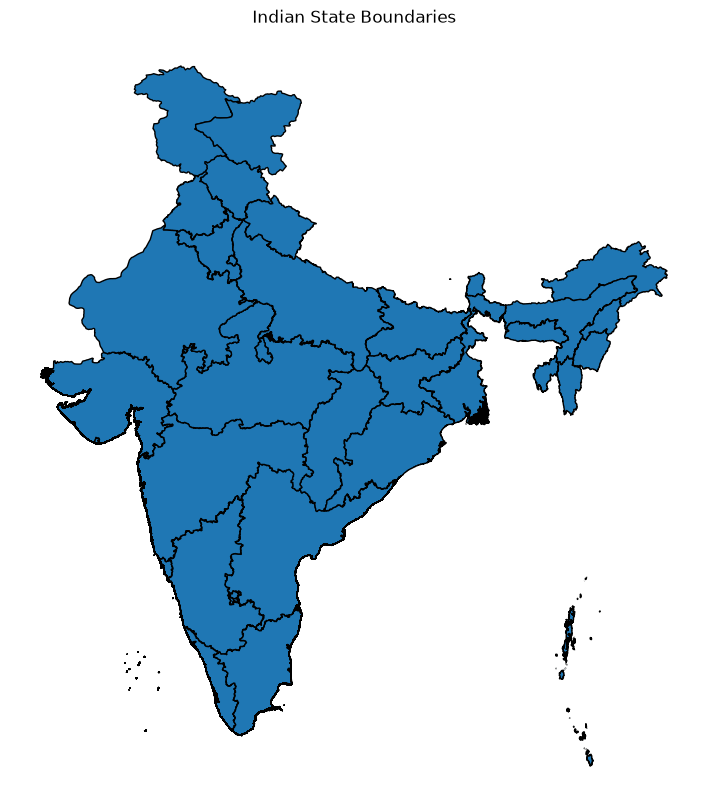

In [24]:
import geopandas as gpd
import matplotlib.pyplot as plt

states = gpd.read_file("india-states-full.geojson")

print(states.columns)

states.plot(edgecolor="black", figsize=(10, 10))
plt.title("Indian State Boundaries")
plt.axis("off")
plt.show()

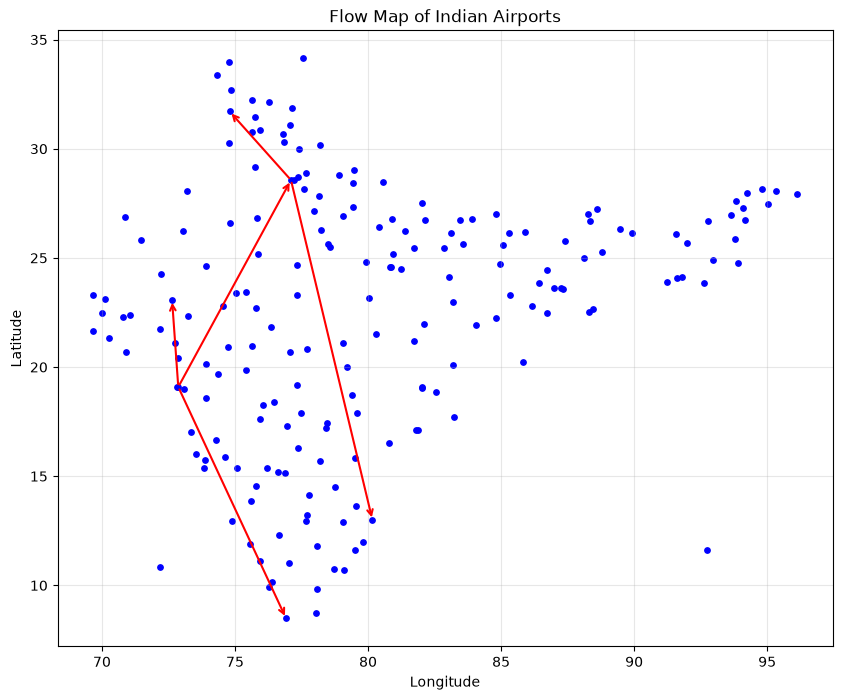

In [31]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("airports-india.csv")
df.columns = df.columns.str.strip()

# Remove duplicate airport names
df = df.drop_duplicates(subset="name", keep="first")

routes = [
    ("Mumbai Airport", "Indira Gandhi International Airport"),
    ("Indira Gandhi International Airport", "Chennai International Airport"),
    ("Mumbai Airport", "Sardar Vallabhbhai Patel International Airport"),
    ("Indira Gandhi International Airport", "Sri Guru Ram Dass Jee International Airport"),
    ("Mumbai Airport", "Trivandrum International Airport")
]

coords = df.set_index("name")[["latitude", "longitude"]].to_dict("index")

plt.figure(figsize=(10, 8))
plt.scatter(df["longitude"], df["latitude"], color="blue", s=15)

for src, dst in routes:
    if src in coords and dst in coords:
        a, b = coords[src], coords[dst]
        plt.annotate(
            "", xy=(b["longitude"], b["latitude"]),
            xytext=(a["longitude"], a["latitude"]),
            arrowprops=dict(arrowstyle="->", color="red", lw=1.5)
        )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Flow Map of Indian Airports")
plt.grid(alpha=0.3)
plt.show()



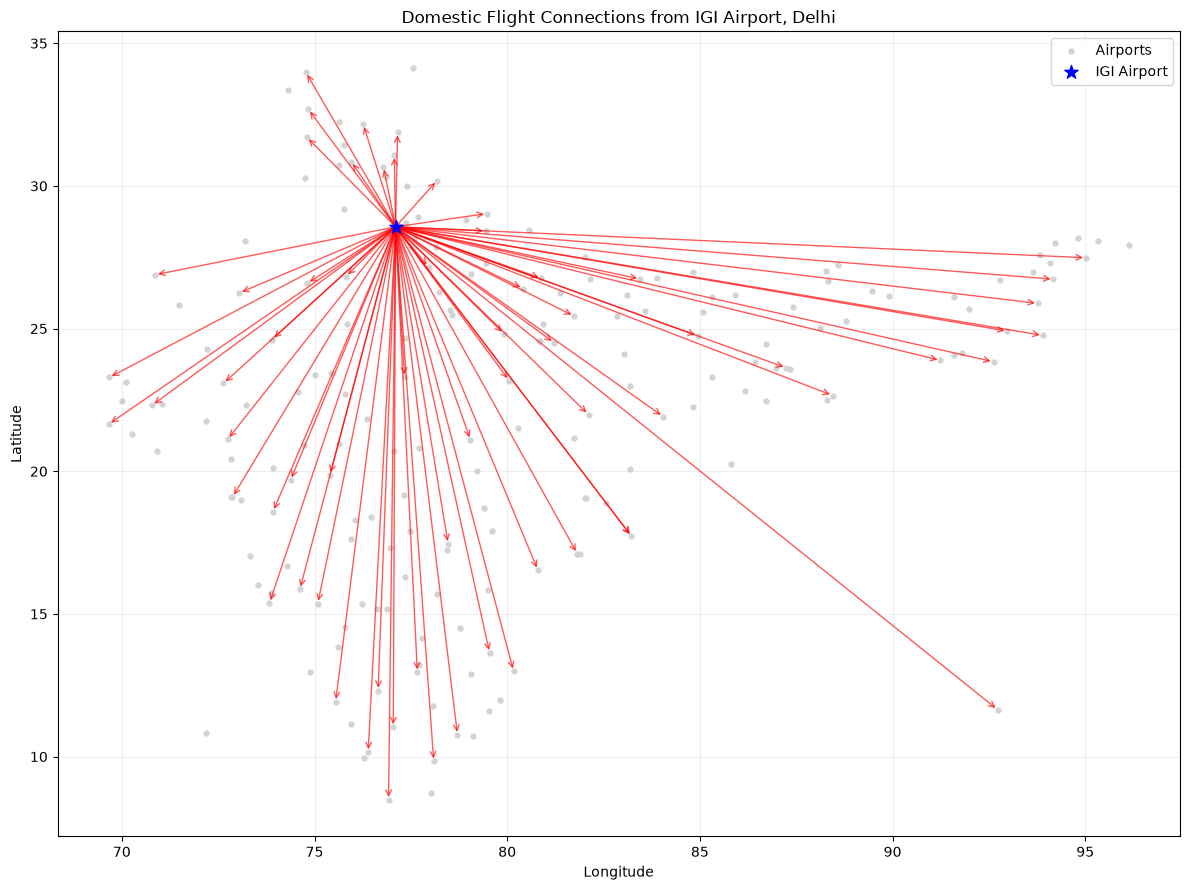

Destinations matched: 66
Destinations not found: ['Mangaluru', 'Nashik', 'Bikaner', 'Vadodara', 'Raipur', 'Purnia', 'Indore', 'Ranchi', 'Bhubaneswar', 'Leh']

Matched airports:
              city                                           name
            Mumbai                                 Mumbai Airport
         Bengaluru                          HAL Bangalore Airport
              Pune                                   Pune Airport
         Hyderabad                          Hyderabad Old Airport
           Kolkata                                Kolkata Airport
         Ahmedabad Sardar Vallabhbhai Patel International Airport
           Chennai                  Chennai International Airport
          Srinagar                 Srinagar International Airport
        Chandigarh               Chandigarh International Airport
           Udaipur                                Udaipur Airport
          Dehradun                            Jolly Grant Airport
             Surat             

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# Load airport dataset
df = pd.read_csv("airports-india.csv")
df.columns = df.columns.str.strip()
df = df.dropna(subset=["latitude", "longitude"])
df = df.drop_duplicates(subset="name")

# IGI Airport coordinates
igi = df[df["name"].str.contains(
    "Indira Gandhi International Airport", case=False, na=False
)]

if igi.empty:
    raise ValueError("IGI Airport not found in airports.csv")

source = igi.iloc[0]
src_lat, src_lon = source["latitude"], source["longitude"]

# Manually compiled domestic destinations from published route listings.
# Aliases help match destination cities to airport names in your CSV.
destinations = {
    "Mumbai": ["Mumbai Airport", "Chhatrapati Shivaji"],
    "Bengaluru": ["Bengaluru", "Bangalore", "Kempegowda"],
    "Pune": ["Pune Airport", "Pune"],
    "Hyderabad": ["Hyderabad", "Rajiv Gandhi"],
    "Kolkata": ["Kolkata", "Netaji Subhas"],
    "Ahmedabad": ["Sardar Vallabhbhai Patel", "Ahmedabad"],
    "Chennai": ["Chennai International Airport"],
    "Srinagar": ["Srinagar"],
    "Chandigarh": ["Chandigarh"],
    "Udaipur": ["Udaipur"],
    "Dehradun": ["Dehradun", "Jolly Grant"],
    "Surat": ["Surat"],
    "Jaipur": ["Jaipur"],
    "Thiruvananthapuram": ["Trivandrum", "Thiruvananthapuram"],
    "Visakhapatnam": ["Visakhapatnam", "Vizag"],
    "Gorakhpur": ["Gorakhpur"],
    "Rajkot": ["Rajkot"],
    "Coimbatore": ["Coimbatore"],
    "Jodhpur": ["Jodhpur"],
    "Imphal": ["Imphal"],
    "Port Blair": ["Port Blair"],
    "Jammu": ["Jammu"],
    "Jabalpur": ["Jabalpur"],
    "Mangaluru": ["Mangalore", "Mangaluru"],
    "Gaya": ["Gaya"],
    "Nashik": ["Nashik"],
    "Dharamshala": ["Dharamshala", "Kangra"],
    "Agartala": ["Agartala"],
    "Aizawl": ["Aizawl"],
    "Shirdi": ["Shirdi"],
    "Jharsuguda": ["Jharsuguda"],
    "Durgapur": ["Durgapur", "Kazi Nazrul"],
    "Kanpur": ["Kanpur"],
    "Madurai": ["Madurai"],
    "Bikaner": ["Bikaner"],
    "Pantnagar": ["Pantnagar"],
    "Shimla": ["Shimla"],
    "Kullu": ["Kullu", "Bhuntar"],
    "Ludhiana": ["Ludhiana"],
    "Bareilly": ["Bareilly"],
    "Bilaspur": ["Bilaspur"],
    "Kishangarh": ["Kishangarh"],
    "Rewa": ["Rewa"],
    "Vadodara": ["Vadodara"],
    "Raipur": ["Raipur"],
    "Purnia": ["Purnia"],
    "Tirupati": ["Tirupati"],
    "Kannur": ["Kannur"],
    "Rajahmundry": ["Rajahmundry"],
    "Jorhat": ["Jorhat"],
    "Khajuraho": ["Khajuraho"],
    "Jammu": ["Jammu"],
    "Mysuru": ["Mysore", "Mysuru"],
    "Amritsar": ["Sri Guru Ram Dass Jee"],
    "Lucknow": ["Lucknow", "Chaudhary Charan Singh"],
    "Patna": ["Patna"],
    "Bhopal": ["Bhopal"],
    "Indore": ["Indore"],
    "Nagpur": ["Nagpur"],
    "Goa": ["Goa", "Dabolim", "Manohar"],
    "Kochi": ["Kochi", "Cochin"],
    "Ranchi": ["Ranchi"],
    "Bhubaneswar": ["Bhubaneswar"],
    "Vijayawada": ["Vijayawada"],
    "Tiruchirappalli": ["Tiruchirappalli", "Trichy"],
    "Agra": ["Agra"],
    "Prayagraj": ["Prayagraj", "Allahabad"],
    "Aurangabad": ["Aurangabad"],
    "Belagavi": ["Belgaum", "Belagavi"],
    "Hubballi": ["Hubli", "Hubballi"],
    "Silchar": ["Silchar"],
    "Dibrugarh": ["Dibrugarh"],
    "Dimapur": ["Dimapur"],
    "Leh": ["Leh"],
    "Bhuj": ["Bhuj"],
    "Jaisalmer": ["Jaisalmer"],
    "Porbandar": ["Porbandar"]
}

# Match destination names against the airport dataset
matched = []
unmatched = []

for city, aliases in destinations.items():
    found = None

    for alias in aliases:
        result = df[df["name"].str.contains(
            alias, case=False, na=False, regex=False
        )]

        if not result.empty:
            # Avoid accidentally selecting IGI itself
            result = result[
                result["name"] != source["name"]
            ]

            if not result.empty:
                found = result.iloc[0]
                break

    if found is not None:
        matched.append({
            "city": city,
            "name": found["name"],
            "latitude": found["latitude"],
            "longitude": found["longitude"]
        })
    else:
        unmatched.append(city)

# Plot flow map
plt.figure(figsize=(12, 9))

# Plot all airports
plt.scatter(
    df["longitude"], df["latitude"],
    color="lightgray", s=12, label="Airports"
)

# Highlight IGI
plt.scatter(
    src_lon, src_lat,
    color="blue", s=100, marker="*", label="IGI Airport",
    zorder=5
)

# Draw routes
for airport in matched:
    plt.annotate(
        "",
        xy=(airport["longitude"], airport["latitude"]),
        xytext=(src_lon, src_lat),
        arrowprops=dict(
            arrowstyle="->",
            color="red",
            linewidth=1,
            alpha=0.65
        )
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Domestic Flight Connections from IGI Airport, Delhi")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Destinations matched:", len(matched))
print("Destinations not found:", unmatched)
print("\nMatched airports:")
print(pd.DataFrame(matched)[["city", "name"]].to_string(index=False))